# Part-2: Data Preprocessing for Time Series

**Time Series in Machine Learning** — Daneshkar.net

---


In [ ]:
# Install required packages (uncomment if needed)
# %pip install numpy
# %pip install pandas
# %pip install matplotlib
# %pip install statsmodels
# %pip install scipy
# %pip install scikit-learn

# Or install all at once:
# %pip install numpy pandas matplotlib statsmodels scipy scikit-learn


In [1]:
# Common imports & Jupyter setup
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
print("Setup complete! Ready to run.")


Setup complete! Ready to run.


---
## Data Cleaning Missing Values


In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.impute import KNNImputer
import os, warnings
warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)


## Section 1: Creating Sample Data with Issues


Section 1: Creating Data with Missing Values & Outliers
  Total records: 200
  Missing values: 11
  Missing percentage: 5.5%
  Missing dates (gaps): 0


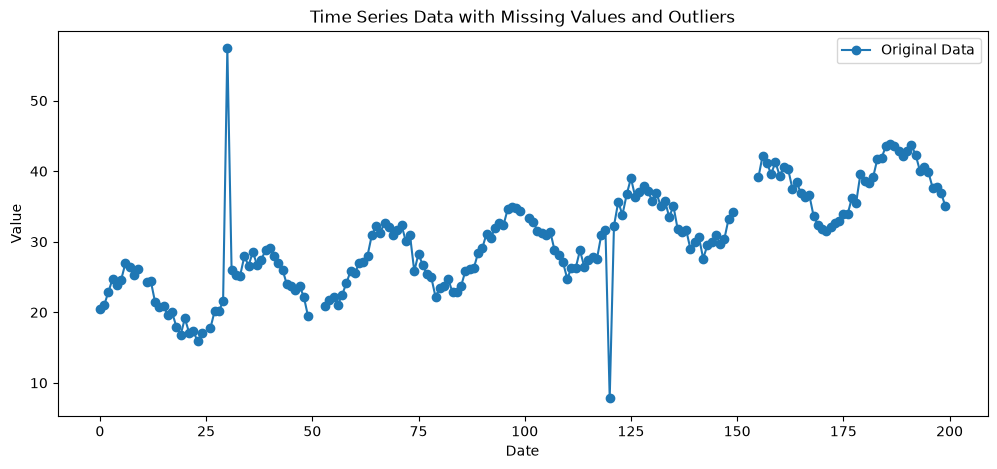

In [3]:
print("=" * 60)
print("Section 1: Creating Data with Missing Values & Outliers")
print("=" * 60)

dates = pd.date_range('2023-01-01', periods=200, freq='D')
values = 20 + 0.1 * np.arange(200) + 5 * np.sin(2 * np.pi * np.arange(200) / 30)
values += np.random.normal(0, 1, 200)

# Introduce missing values
missing_indices = [10, 25, 50, 51, 52, 100, 150, 151, 152, 153, 154]
values[missing_indices] = np.nan

# Introduce outliers
values[30] = values[30] + 35
values[120] = values[120] - 25

df = pd.DataFrame({'value': values}, index=dates)
print(f"  Total records: {len(df)}")
print(f"  Missing values: {df['value'].isnull().sum()}")
print(f"  Missing percentage: {df['value'].isnull().sum()/len(df)*100:.1f}%")

# Check for missing dates in a daily series
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='D')
missing_dates = full_range.difference(df.index)
print(f"  Missing dates (gaps): {len(missing_dates)}")
plt.plot(values, label='Original Data', marker='o')
plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Time Series Data with Missing Values and Outliers')
plt.legend()
plt.show()


## Section 2: Handling Missing Values



Section 2: Missing Value Imputation Methods


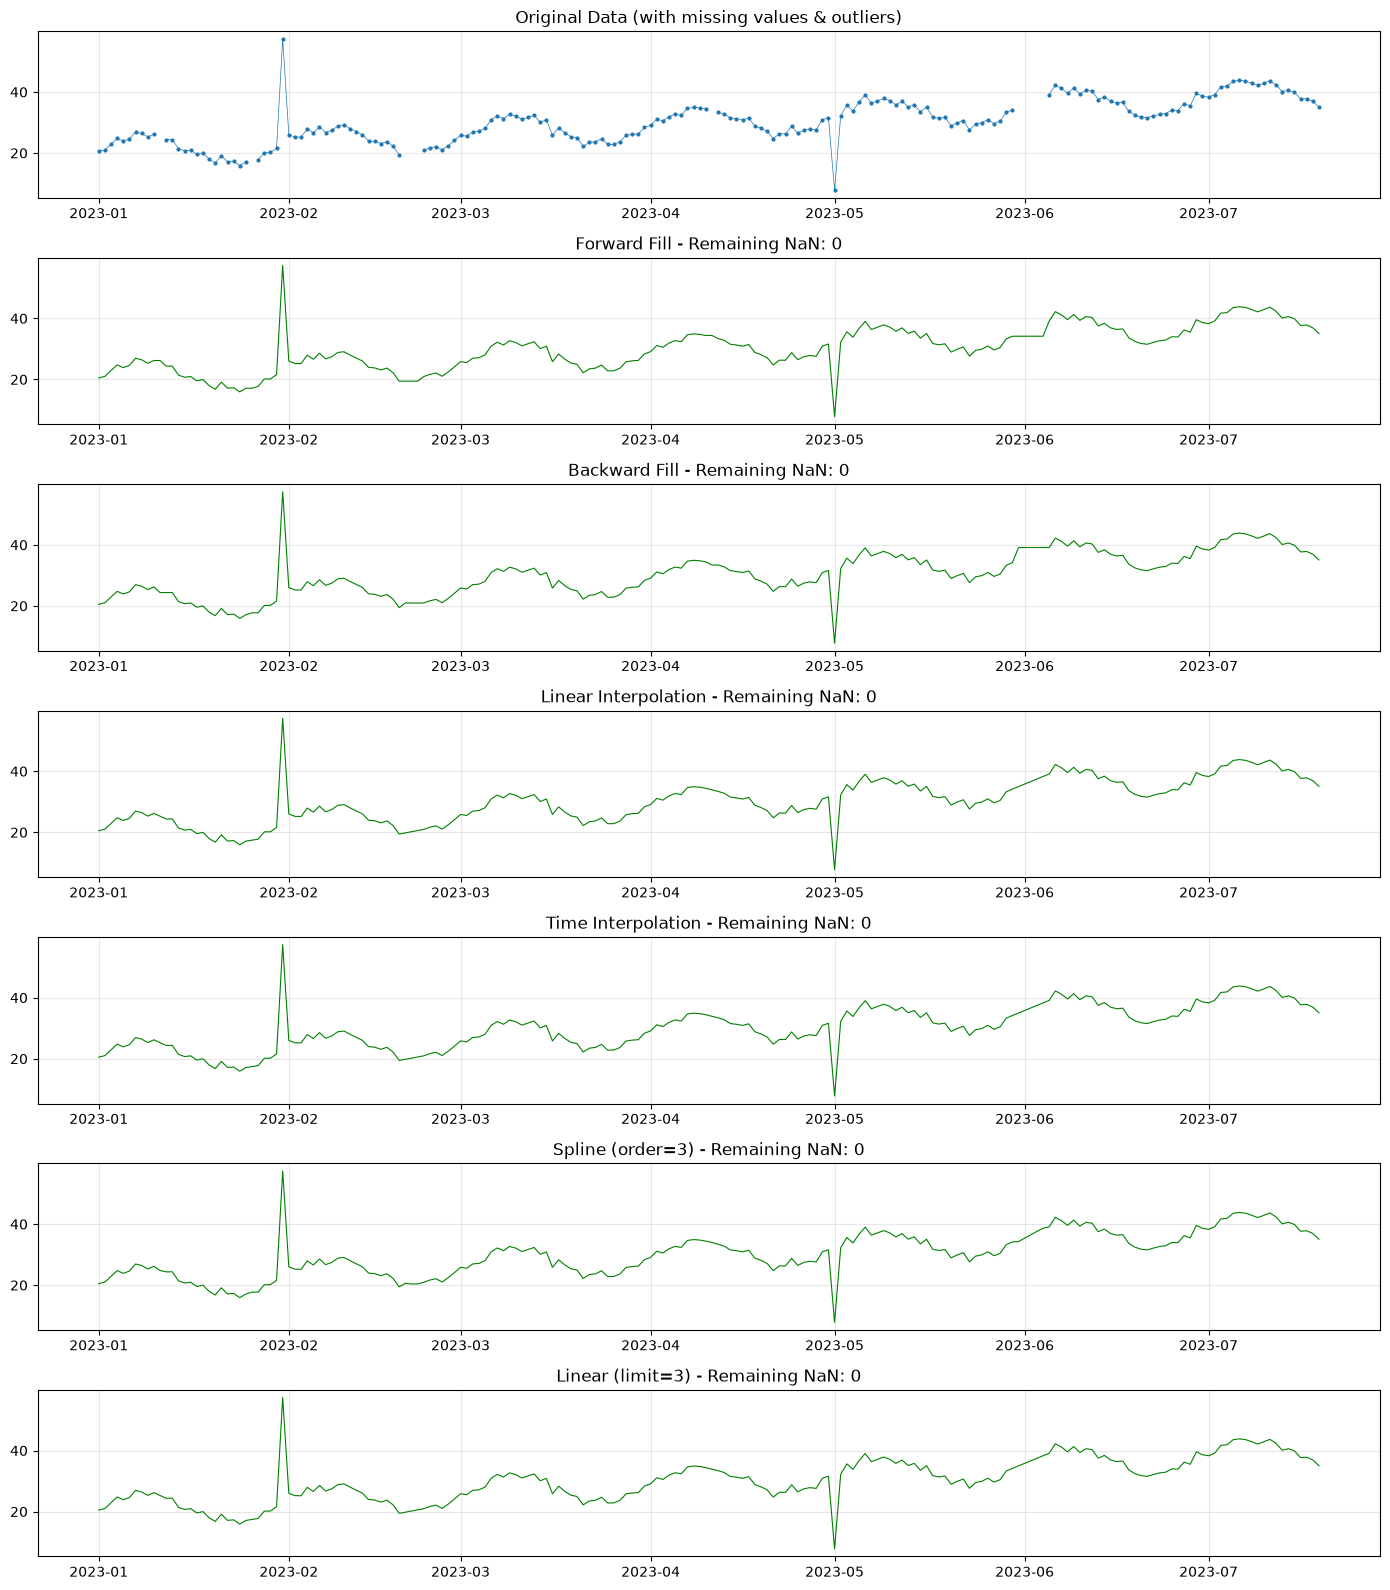

In [4]:
print("\n" + "=" * 60)
print("Section 2: Missing Value Imputation Methods")
print("=" * 60)

methods = {
    'Forward Fill': df['value'].ffill(),
    'Backward Fill': df['value'].bfill(),
    'Linear Interpolation': df['value'].interpolate(method='linear'),
    'Time Interpolation': df['value'].interpolate(method='time'),
    'Spline (order=3)': df['value'].interpolate(method='spline', order=3),
    'Linear (limit=3)': df['value'].interpolate(method='linear', limit=3, limit_direction='both'),
}

fig, axes = plt.subplots(len(methods) + 1, 1, figsize=(14, 16))
axes[0].plot(df.index, df['value'], 'o-', markersize=2, linewidth=0.5)
axes[0].set_title('Original Data (with missing values & outliers)')
axes[0].grid(True, alpha=0.3)

for ax, (name, filled) in zip(axes[1:], methods.items()):
    ax.plot(df.index, filled, linewidth=0.8, color='green')
    ax.set_title(f'{name} - Remaining NaN: {filled.isnull().sum()}')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '01_missing_value_methods.png'), dpi=100)


## Section 3: Seasonal Fill



Section 3: Seasonal Fill
  Seasonal fill (weekday mean): remaining NaN = 0


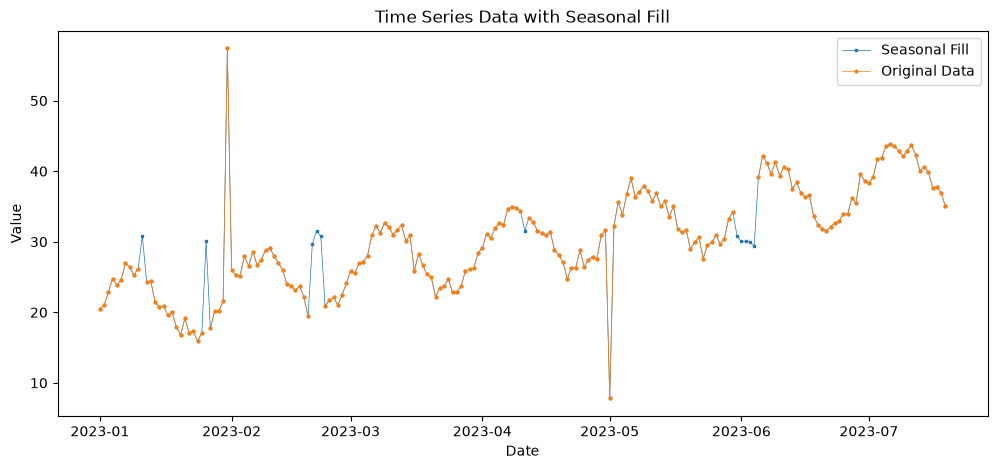

In [8]:
print("\n" + "=" * 60)
print("Section 3: Seasonal Fill")
print("=" * 60)

df_filled = df.copy()
# Fill using same weekday mean
df_filled['weekday'] = df_filled.index.dayofweek
weekday_means = df_filled.groupby('weekday')['value'].transform('mean')
df_filled['value'] = df_filled['value'].fillna(weekday_means)
print(f"  Seasonal fill (weekday mean): remaining NaN = {df_filled['value'].isnull().sum()}")

plt.plot(df_filled.index, df_filled['value'], 's-', markersize=2, linewidth=0.5, label='Seasonal Fill')
plt.plot(df.index, df['value'], 'o-', markersize=2, linewidth=0.5, label='Original Data')

plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Time Series Data with Seasonal Fill')
plt.legend()
plt.show()

## Section 4: Outlier Detection


In [11]:
print("\n" + "=" * 60)
print("Section 4: Outlier Detection Methods")
print("=" * 60)

clean_values = df['value'].dropna()

#==========================
# Method 1: Z-Score
#==========================
z_scores = np.abs(stats.zscore(clean_values))
outliers_z = np.where(z_scores > 3)[0]
print(f"  Z-Score (>3 sigma): {len(outliers_z)} outliers at indices {outliers_z.tolist()}")

#==========================
# Method 2: IQR
#==========================
Q1, Q3 = clean_values.quantile(0.25), clean_values.quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers_iqr = clean_values[(clean_values < lower) | (clean_values > upper)]
print(f"  IQR: bounds=[{lower:.2f}, {upper:.2f}], {len(outliers_iqr)} outliers")

#==========================
# Method 3: Rolling window (local context)
#==========================
rolling_mean = df['value'].rolling(window=14, center=True, min_periods=1).mean()
rolling_std = df['value'].rolling(window=14, center=True, min_periods=1).std()
rolling_outliers = np.abs(df['value'] - rolling_mean) > 3 * rolling_std
print(f"  Rolling Window: {rolling_outliers.sum()} outliers detected")

#==========================
# Method 4: Isolation Forest (for multivariate)
#==========================
iso_data = df[['value']].dropna()
iso_forest = IsolationForest(contamination=0.05, random_state=42)
iso_labels = iso_forest.fit_predict(iso_data)
print(f"  Isolation Forest: {(iso_labels == -1).sum()} outliers detected")



Section 4: Outlier Detection Methods
  Z-Score (>3 sigma): 2 outliers at indices [28, 114]
  IQR: bounds=[10.48, 49.79], 2 outliers
  Rolling Window: 1 outliers detected
  Isolation Forest: 10 outliers detected


## Section 5: Handling Outliers


In [ ]:
print("\n" + "=" * 60)
print("Section 5: Outlier Treatment Methods")
print("=" * 60)

df_clean = df.copy()

# Winsorization (clip to percentiles)
lower_pct = df_clean['value'].quantile(0.01)
upper_pct = df_clean['value'].quantile(0.99)
df_clean['winsorized'] = df_clean['value'].clip(lower_pct, upper_pct)
print(f"  Winsorization: clipped to [{lower_pct:.2f}, {upper_pct:.2f}]")

# Log transform to reduce impact of large values
df_clean['log_transformed'] = np.log1p(df_clean['value'].clip(lower=0))
print(f"  Log transform applied")

# Replace outliers with rolling median
z = np.abs(stats.zscore(df_clean['value'].fillna(df_clean['value'].median())))
outlier_mask = z > 3
rolling_median = df_clean['value'].rolling(window=7, center=True, min_periods=1).median()
df_clean['replaced'] = df_clean['value'].copy()
df_clean.loc[outlier_mask, 'replaced'] = rolling_median[outlier_mask]
print(f"  Replaced {outlier_mask.sum()} outliers with rolling median")



Section 5: Outlier Treatment Methods
  Winsorization: clipped to [16.67, 43.69]
  Log transform applied
  Replaced 2 outliers with rolling median


## Section 6: Complete Cleaning Function



Section 7: Complete Cleaning Pipeline (with Visualization)


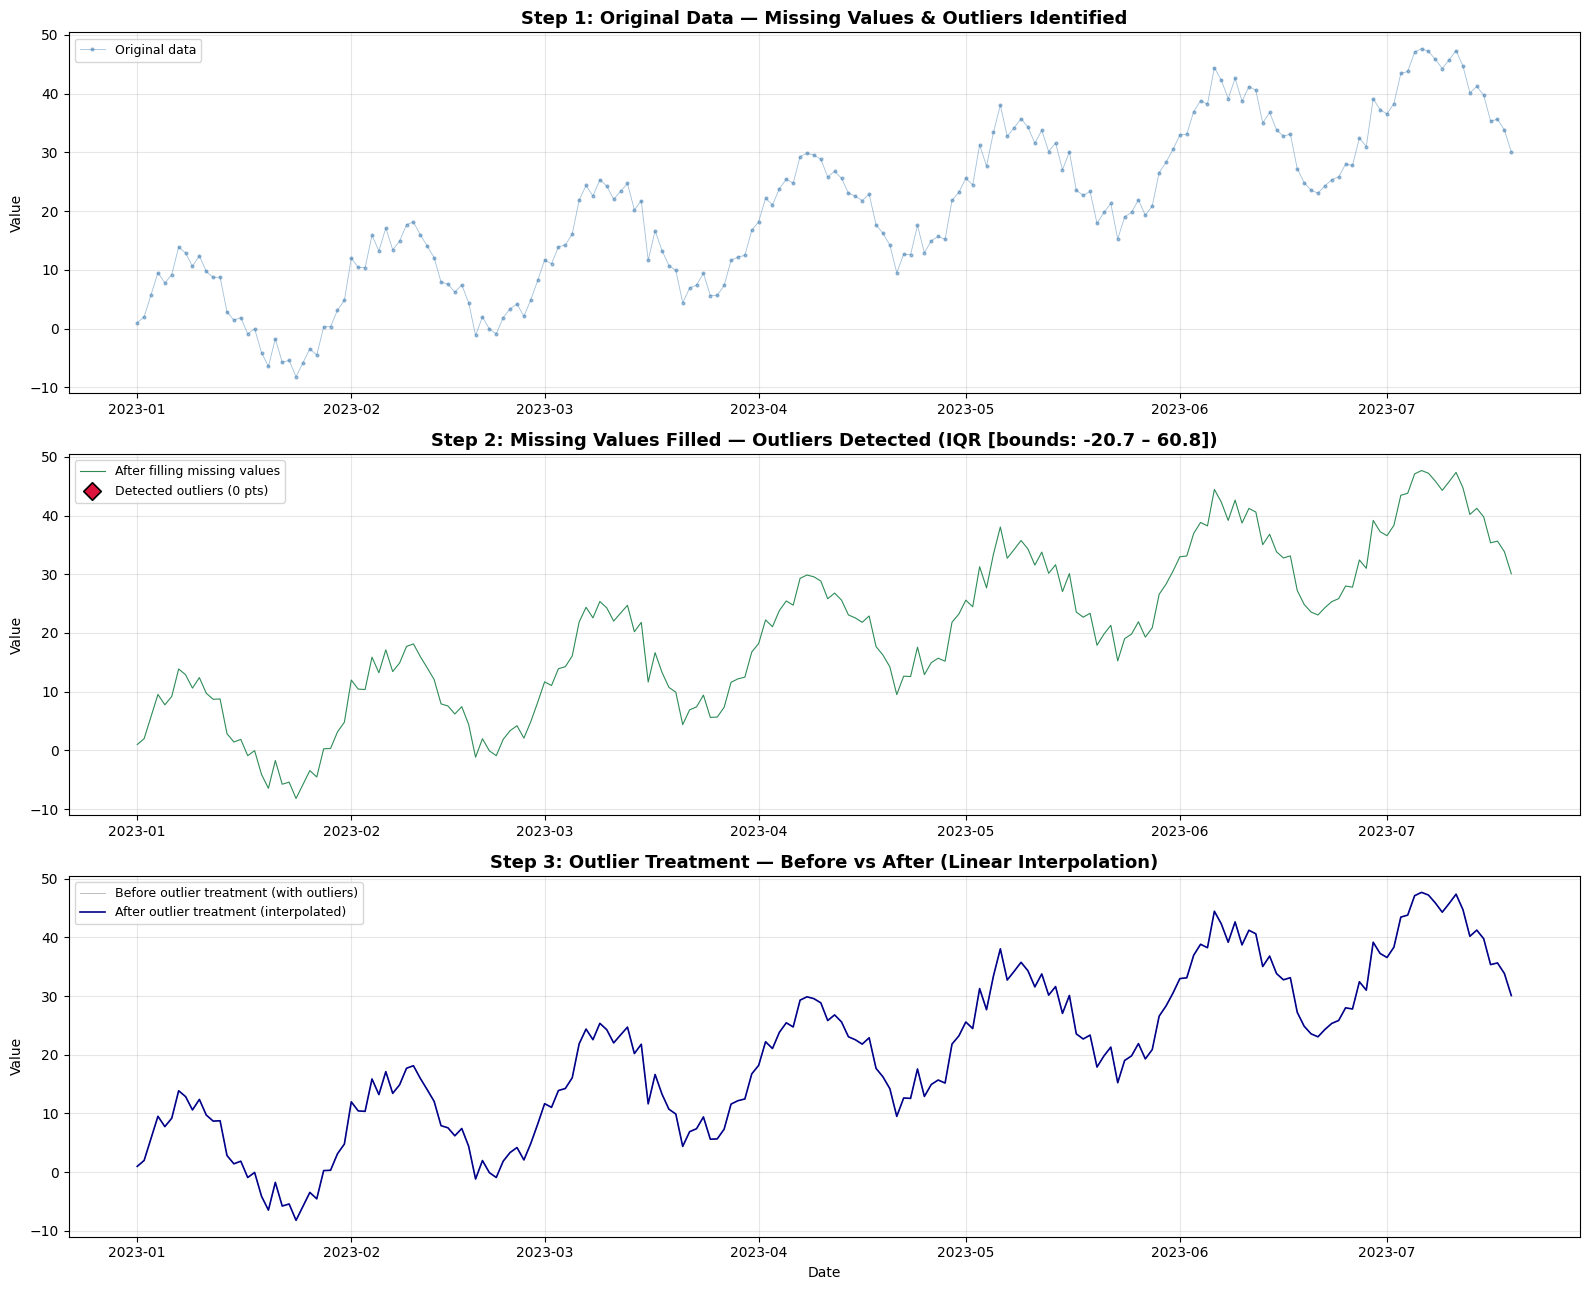

  Missing (input):       0
  Gaps after reindex:    0
  Remaining after fill:  0
  Outliers detected:     0  (method: iqr)
  Remaining after all:   0
  Output shape:          (200, 1)

Done! Data cleaning complete.


In [ ]:
print("\n" + "=" * 60)
print("Section 7: Complete Cleaning Pipeline (with Visualization)")
print("=" * 60)


def clean_time_series(df, value_col, freq='D', fill_method='linear',
                       fill_limit=5, outlier_method='iqr', plot=True):
    """
    Comprehensive time series cleaning function with step-by-step visualization.
    Shows: original → fill missing → detect outliers → replace outliers.
    """
    df = df.copy()
    
    # ═══ Step 0: Store original state ═══
    original = df[value_col].copy()
    
    # ═══ Step 1: Clean index ═══
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    df = df[~df.index.duplicated(keep='first')]
    
    # ═══ Step 2: Reindex to regular frequency ═══
    full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq=freq)
    df = df.reindex(full_range)
    after_reindex = df[value_col].copy()
    
    # ═══ Step 3: Fill missing values ═══
    if fill_method in ['linear', 'time', 'spline']:
        df[value_col] = df[value_col].interpolate(
            method=fill_method, limit=fill_limit, limit_direction='both')
    elif fill_method == 'ffill':
        df[value_col] = df[value_col].ffill(limit=fill_limit)
    elif fill_method == 'bfill':
        df[value_col] = df[value_col].bfill(limit=fill_limit)
    
    after_fill = df[value_col].copy()
    
    # ═══ Step 4: Detect outliers ═══
    if outlier_method == 'iqr':
        Q1 = df[value_col].quantile(0.25)
        Q3 = df[value_col].quantile(0.75)
        IQR = Q3 - Q1
        lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
        outlier_mask = (df[value_col] < lower) | (df[value_col] > upper)
        method_label = f'IQR [bounds: {lower:.1f} – {upper:.1f}]'
        
    elif outlier_method == 'zscore':
        z = np.abs(stats.zscore(df[value_col].fillna(df[value_col].median())))
        outlier_mask = z > 3
        method_label = 'Z-Score (>3σ)'
    else:
        outlier_mask = pd.Series(False, index=df.index)
        method_label = 'None'
    
    outlier_count = outlier_mask.sum()
    
    # ═══ Step 5: Replace outliers with interpolation ═══
    before_treatment = df[value_col].copy()
    df.loc[outlier_mask, value_col] = np.nan
    df[value_col] = df[value_col].interpolate(method='linear')
    after_treatment = df[value_col].copy()
    
    # ═══════════════════════════════════════════════
    #  PLOTTING: 3-panel view
    # ═══════════════════════════════════════════════
    if plot:
        fig, axes = plt.subplots(3, 1, figsize=(16, 13))
        
        # ─── Panel 1: Original data + mark missing + mark outliers ───
        ax = axes[0]
        ax.plot(original.index, original.values,
                'o-', markersize=2, linewidth=0.6,
                color='steelblue', alpha=0.5, label='Original data')
        
        # Highlight missing values with red vertical bands
        missing_mask = original.isnull()
        if missing_mask.any():
            for idx in original[missing_mask].index:
                ax.axvline(x=idx, color='red', alpha=0.12, linewidth=5)
            y_mid = original.mean() if not original.dropna().empty else 0
            ax.scatter(original[missing_mask].index,
                       np.full(missing_mask.sum(), y_mid),
                       color='red', marker='x', s=80, zorder=5,
                       label=f'Missing values ({missing_mask.sum()} pts)')
        
        # Highlight the original outlier points (before any treatment)
        orig_outlier_pts = outlier_mask & ~original.isnull()
        if orig_outlier_pts.any():
            ax.scatter(original[orig_outlier_pts].index,
                       original[orig_outlier_pts].values,
                       color='darkorange', marker='o', s=70,
                       edgecolors='black', linewidths=1.2,
                       zorder=6, label=f'Outlier — raw ({orig_outlier_pts.sum()} pts)')
        
        ax.set_title('Step 1: Original Data — Missing Values & Outliers Identified',
                     fontweight='bold', fontsize=13)
        ax.legend(loc='best', fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_ylabel('Value')
        
        # ─── Panel 2: After fill, show detected outliers ───
        ax = axes[1]
        ax.plot(after_fill.index, after_fill.values,
                linewidth=0.8, color='seagreen',
                label='After filling missing values')
        ax.scatter(after_fill[outlier_mask].index,
                   after_fill[outlier_mask].values,
                   color='crimson', marker='D', s=80,
                   edgecolors='black', linewidths=1.2,
                   zorder=5, label=f'Detected outliers ({outlier_count} pts)')
        ax.set_title(f'Step 2: Missing Values Filled — Outliers Detected ({method_label})',
                     fontweight='bold', fontsize=13)
        ax.legend(loc='best', fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_ylabel('Value')
        
        # ─── Panel 3: Before vs After treatment ───
        ax = axes[2]
        ax.plot(before_treatment.index, before_treatment.values,
                linewidth=0.6, color='gray', alpha=0.6,
                label='Before outlier treatment (with outliers)')
        ax.plot(after_treatment.index, after_treatment.values,
                linewidth=1.2, color='darkblue',
                label='After outlier treatment (interpolated)')
        
        # Shade around outlier points
        for idx in outlier_mask[outlier_mask].index:
            ax.axvspan(idx - pd.Timedelta(hours=12),
                        idx + pd.Timedelta(hours=12),
                        alpha=0.10, color='orange')
        
        if outlier_mask.any():
            ax.scatter(before_treatment[outlier_mask].index,
                       before_treatment[outlier_mask].values,
                       color='crimson', marker='o', s=60,
                       edgecolors='black', linewidths=0.8,
                       zorder=5, label=f'Outlier — original ({outlier_count} pts)')
            ax.scatter(after_treatment[outlier_mask].index,
                       after_treatment[outlier_mask].values,
                       color='darkblue', marker='s', s=60,
                       edgecolors='black', linewidths=0.8,
                       zorder=5, label=f'Outlier — replaced ({outlier_count} pts)')
        
        ax.set_title('Step 3: Outlier Treatment — Before vs After (Linear Interpolation)',
                     fontweight='bold', fontsize=13)
        ax.legend(loc='best', fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_ylabel('Value')
        ax.set_xlabel('Date')
        
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, '07_cleaning_pipeline.png'), dpi=100)
        plt.show()
    
    # ═══ Report ═══
    remaining = df[value_col].isnull().sum()
    print(f"  Missing (input):       {original.isnull().sum()}")
    print(f"  Gaps after reindex:    {after_reindex.isnull().sum()}")
    print(f"  Remaining after fill:  {after_fill.isnull().sum()}")
    print(f"  Outliers detected:     {outlier_count}  (method: {outlier_method})")
    print(f"  Remaining after all:   {remaining}")
    print(f"  Output shape:          {df.shape}")
    return df


# ── Run pipeline ──
cleaned = clean_time_series(df, 'value', outlier_method='iqr')

print("\nDone! Data cleaning complete.")


---
## Lag Features


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from sklearn.feature_selection import mutual_info_regression, SelectKBest, f_regression
import os, warnings

# Try importing seaborn (optional)
try:
    import seaborn as sns
    HAS_SEABORN = True
except ImportError:
    HAS_SEABORN = False
print(HAS_SEABORN)
warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)


True


## Section 1: Creating Data and Basic Lag Features


In [ ]:
print("=" * 60)
print("Section 1: Creating Lag Features")
print("=" * 60)

dates = pd.date_range('2023-01-01', periods=100, freq='D')
df = pd.DataFrame({
    'value': np.sin(2 * np.pi * np.arange(100) / 7) + np.random.normal(0, 0.3, 100) + 10
}, index=dates)

# Basic lags
df['lag_1'] = df['value'].shift(1)
df['lag_2'] = df['value'].shift(2)
df['lag_7'] = df['value'].shift(7)

print("  Sample with lag features:")
print(df.head(10).round(3).to_string())
print(f"\n  Autocorrelation (lag=1): {df['value'].autocorr(lag=1):.4f}")
print(f"  Autocorrelation (lag=7): {df['value'].autocorr(lag=7):.4f}")


Section 1: Creating Lag Features
  Sample with lag features:
             value   lag_1   lag_2   lag_7
2023-01-01  10.149     NaN     NaN     NaN
2023-01-02  10.740  10.149     NaN     NaN
2023-01-03  11.169  10.740  10.149     NaN
2023-01-04  10.891  11.169  10.740     NaN
2023-01-05   9.496  10.891  11.169     NaN
2023-01-06   8.955   9.496  10.891     NaN
2023-01-07   9.692   8.955   9.496     NaN
2023-01-08  10.230   9.692   8.955  10.149
2023-01-09  10.641  10.230   9.692  10.740
2023-01-10  11.138  10.641  10.230  11.169

  Autocorrelation (lag=1): 0.5333
  Autocorrelation (lag=7): 0.8590


## Section 2: ACF and PACF Analysis



Section 2: ACF and PACF for Lag Selection
  Significant ACF lags: [0, 2, 3, 5, 6, 7, 9, 10, 13, 16]
  Significant PACF lags: [0, 1, 2, 3, 6, 9, 11, 13, 26]


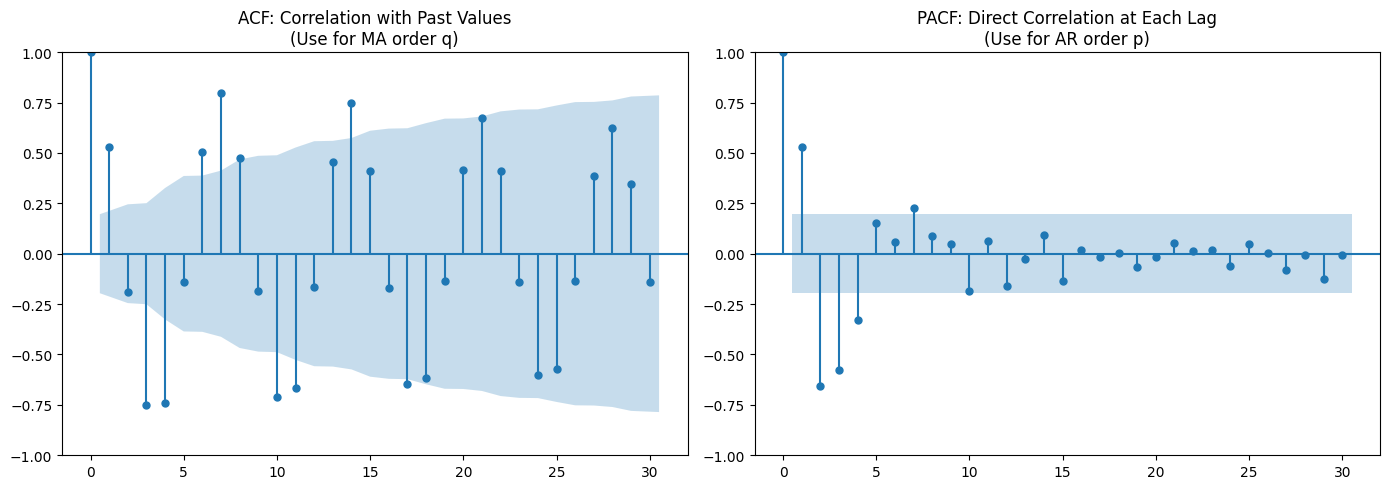

In [ ]:
print("\n" + "=" * 60)
print("Section 2: ACF and PACF for Lag Selection")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(df['value'].dropna(), lags=30, ax=axes[0])
axes[0].set_title('ACF: Correlation with Past Values\n(Use for MA order q)')
plot_pacf(df['value'].dropna(), lags=30, ax=axes[1])
axes[1].set_title('PACF: Direct Correlation at Each Lag\n(Use for AR order p)')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '02_acf_pacf.png'), dpi=100)
# Significant lags
acf_vals, acf_conf = acf(df['value'].dropna(), nlags=30, alpha=0.05)
pacf_vals, pacf_conf = pacf(df['value'].dropna(), nlags=30, alpha=0.05)

sig_acf = np.where(np.abs(acf_vals[1:]) > (acf_conf[1:, 1] - acf_vals[1:]))[0]
sig_pacf = np.where(np.abs(pacf_vals[1:]) > (pacf_conf[1:, 1] - pacf_vals[1:]))[0]
print(f"  Significant ACF lags: {sig_acf.tolist()}")
print(f"  Significant PACF lags: {sig_pacf.tolist()}")


## Section 3: Automated Lag Feature Creation


In [ ]:
print("\n" + "=" * 60)
print("Section 3: Automated Lag Feature Creation")
print("=" * 60)


def create_lag_features(df, target_col, lags):
    """Create multiple lag features at once."""
    df = df.copy()
    for lag in lags:
        df[f'{target_col}_lag_{lag}'] = df[target_col].shift(lag)
    return df


df_lags = create_lag_features(df, 'value', [1, 2, 3, 5, 7, 14])
print(f"  Created {sum(1 for c in df_lags.columns if 'lag_' in c)} lag features")



Section 3: Automated Lag Feature Creation
  Created 9 lag features


## Section 4: Types of Lag Features


In [ ]:
print("\n" + "=" * 60)
print("Section 4: Types of Lag Features")
print("=" * 60)

# Simple lag
df['simple_lag'] = df['value'].shift(1)

# Seasonal lag
df['seasonal_lag_7'] = df['value'].shift(7)

# Differenced lag (change from previous)
df['diff_lag'] = df['value'].diff(1)

# Percentage change lag
df['pct_change_lag'] = df['value'].pct_change(1)

print("  Types of lag features:")
print(df[['value', 'simple_lag', 'seasonal_lag_7', 'diff_lag', 'pct_change_lag']].tail(10).round(3).to_string())



Section 4: Types of Lag Features
  Types of lag features:
             value  simple_lag  seasonal_lag_7  diff_lag  pct_change_lag
2023-04-01   9.247       9.179           9.063     0.068           0.007
2023-04-02  10.291       9.247           9.757     1.043           0.113
2023-04-03  10.571      10.291          10.631     0.281           0.027
2023-04-04  10.877      10.571          11.250     0.305           0.029
2023-04-05  10.316      10.877          10.533    -0.560          -0.052
2023-04-06   9.127      10.316           9.407    -1.189          -0.115
2023-04-07   9.114       9.127           9.179    -0.013          -0.001
2023-04-08   9.296       9.114           9.247     0.183           0.020
2023-04-09  10.002       9.296          10.291     0.705           0.076
2023-04-10  10.711      10.002          10.571     0.710           0.071


## Section 5: Lag Feature Importance


In [ ]:
print("\n" + "=" * 60)
print("Section 5: Lag Feature Importance Analysis")
print("=" * 60)

# Create target (next step)
df['target'] = df['value'].shift(-1)

# Create many lags
lags_to_test = list(range(1, 21))
df_ml = create_lag_features(df, 'value', lags_to_test)
df_ml = df_ml.dropna()

# Correlation with target
lag_cols = [f'value_lag_{l}' for l in lags_to_test]
correlations = df_ml[lag_cols].corrwith(df_ml['target']).abs().sort_values(ascending=False)
print("  Top 5 lags by correlation with target:")
for col, corr in correlations.head(5).items():
    print(f"    {col}: {corr:.4f}")

# Mutual Information
X = df_ml[lag_cols]
y = df_ml['target']
mi_scores = mutual_info_regression(X, y, random_state=42)
mi_series = pd.Series(mi_scores, index=lag_cols).sort_values(ascending=False)
print("\n  Top 5 lags by Mutual Information:")
for col, mi in mi_series.head(5).items():
    print(f"    {col}: {mi:.4f}")



Section 5: Lag Feature Importance Analysis
  Top 5 lags by correlation with target:
    value_lag_13: 0.8822
    value_lag_6: 0.8725
    value_lag_20: 0.8530
    value_lag_2: 0.7919
    value_lag_9: 0.7892

  Top 5 lags by Mutual Information:
    value_lag_13: 0.8293
    value_lag_6: 0.7292
    value_lag_20: 0.6956
    value_lag_16: 0.6198
    value_lag_9: 0.5642


## Section 6: Correlation Heatmap of Lag Features



Section 6: Lag Feature Multicollinearity


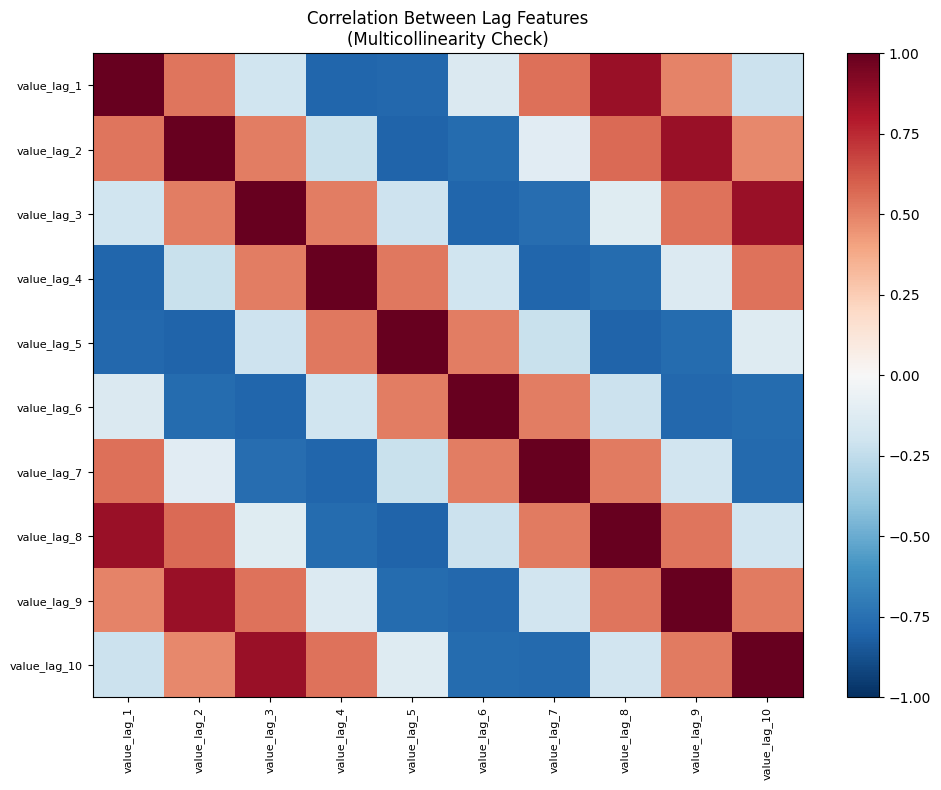

In [ ]:
print("\n" + "=" * 60)
print("Section 6: Lag Feature Multicollinearity")
print("=" * 60)

corr_matrix = df_ml[lag_cols[:10]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
if HAS_SEABORN:
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax,
                vmin=-1, vmax=1, square=True, linewidths=0.5)
else:
    im = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    plt.colorbar(im, ax=ax)
    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_yticks(range(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns, rotation=90, fontsize=8)
    ax.set_yticklabels(corr_matrix.columns, fontsize=8)
ax.set_title('Correlation Between Lag Features\n(Multicollinearity Check)')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '02_lag_correlation.png'), dpi=100)


## Section 7: Prepare Data for ML


In [ ]:
print("\n" + "=" * 60)
print("Section 7: Preparing Time Series Data for ML")
print("=" * 60)


def prepare_ts_data_for_ml(df, target_col, lags, window_sizes=None):
    """Prepare time series data for machine learning models."""
    df = df.copy()
    # Lag features
    for lag in lags:
        df[f'{target_col}_lag_{lag}'] = df[target_col].shift(lag)
    # Window features
    if window_sizes:
        for w in window_sizes:
            roll = df[target_col].shift(1).rolling(w)
            df[f'{target_col}_rmean_{w}'] = roll.mean()
            df[f'{target_col}_rstd_{w}'] = roll.std()
    # Target
    df['target'] = df[target_col].shift(-1)
    # Drop NaN
    df = df.dropna()
    return df


df_ready = prepare_ts_data_for_ml(df, 'value', lags=[1, 2, 3, 7, 14], window_sizes=[7, 14])
print(f"  Ready for ML: {df_ready.shape[0]} samples, {df_ready.shape[1]} features")
print(f"  Feature columns: {[c for c in df_ready.columns if c not in ['value', 'target']]}")

print("\nDone! Lag features analysis complete.")



Section 7: Preparing Time Series Data for ML
  Ready for ML: 85 samples, 18 features
  Feature columns: ['lag_1', 'lag_2', 'lag_7', 'simple_lag', 'seasonal_lag_7', 'diff_lag', 'pct_change_lag', 'value_lag_1', 'value_lag_2', 'value_lag_3', 'value_lag_7', 'value_lag_14', 'value_rmean_7', 'value_rstd_7', 'value_rmean_14', 'value_rstd_14']

Done! Lag features analysis complete.


---
## Sliding Windows


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import os, warnings
warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)


## Section 1: Create Sample Data


Section 1: Rolling Window Statistics
            value  rmean_7  rstd_7  rmin_7  rmax_7
2023-07-10  51.94    54.11    1.62   51.94   56.03
2023-07-11  51.57    54.00    1.79   51.57   56.03
2023-07-12  50.23    53.41    2.27   50.23   56.03
2023-07-13  47.17    52.19    3.01   47.17   56.03
2023-07-14  45.35    50.67    3.42   45.35   55.18
2023-07-15  43.66    49.02    3.65   43.66   53.23
2023-07-16  40.70    47.23    4.26   40.70   51.94
2023-07-17  38.86    45.36    4.70   38.86   51.57
2023-07-18  37.11    43.30    4.69   37.11   50.23
2023-07-19  34.41    41.04    4.61   34.41   47.17


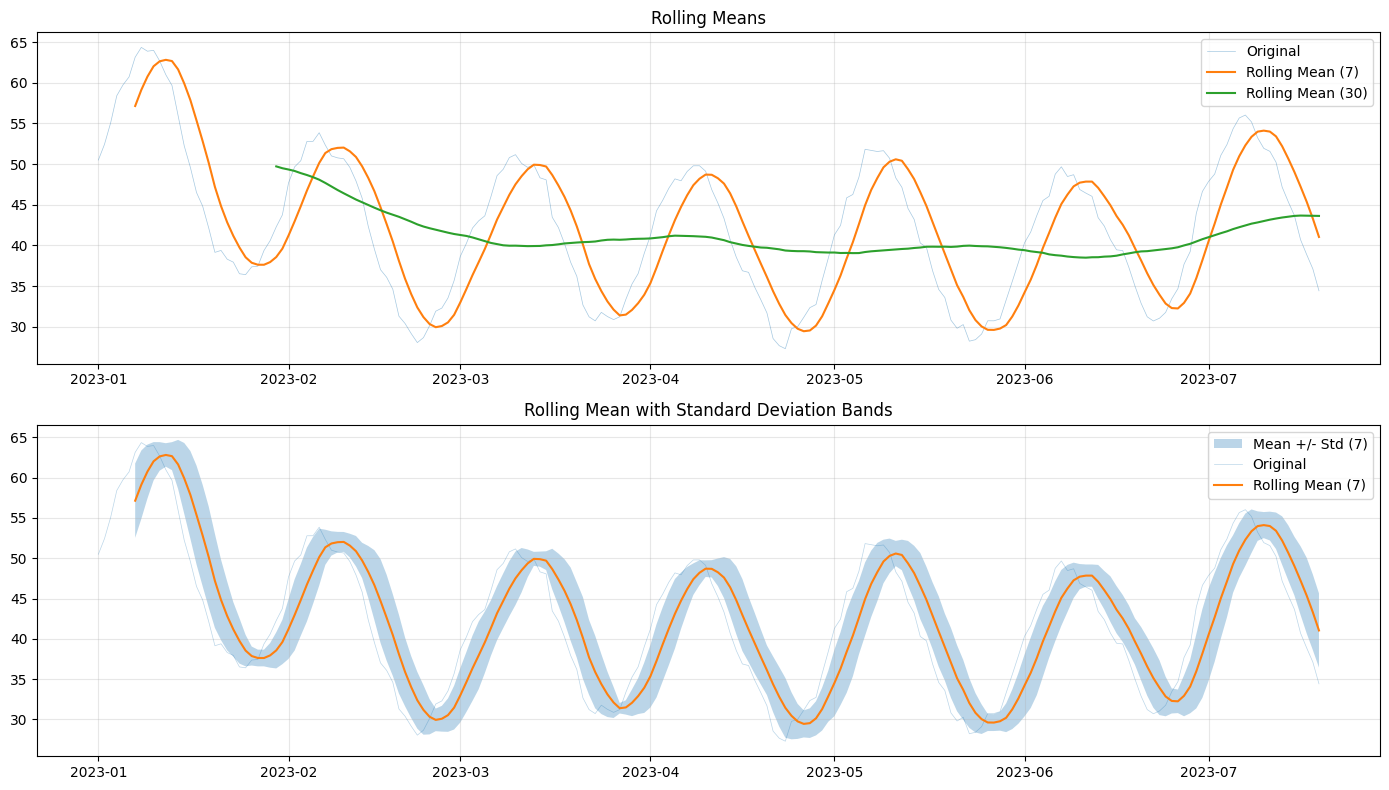

In [ ]:
print("=" * 60)
print("Section 1: Rolling Window Statistics")
print("=" * 60)

dates = pd.date_range('2023-01-01', periods=200, freq='D')
df = pd.DataFrame({
    'value': np.cumsum(np.random.normal(0, 1, 200)) + 50 + 10 * np.sin(2 * np.pi * np.arange(200) / 30)
}, index=dates)

# Rolling statistics
df['rmean_7'] = df['value'].rolling(window=7).mean()
df['rmean_30'] = df['value'].rolling(window=30).mean()
df['rstd_7'] = df['value'].rolling(window=7).std()
df['rmin_7'] = df['value'].rolling(window=7).min()
df['rmax_7'] = df['value'].rolling(window=7).max()
df['rmedian_7'] = df['value'].rolling(window=7).median()

print(df[['value', 'rmean_7', 'rstd_7', 'rmin_7', 'rmax_7']].tail(10).round(2).to_string())

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(df['value'], alpha=0.4, linewidth=0.5, label='Original')
axes[0].plot(df['rmean_7'], linewidth=1.5, label='Rolling Mean (7)')
axes[0].plot(df['rmean_30'], linewidth=1.5, label='Rolling Mean (30)')
axes[0].set_title('Rolling Means')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].fill_between(df.index, df['rmean_7'] - df['rstd_7'], df['rmean_7'] + df['rstd_7'],
                      alpha=0.3, label='Mean +/- Std (7)')
axes[1].plot(df['value'], alpha=0.3, linewidth=0.5, label='Original')
axes[1].plot(df['rmean_7'], linewidth=1.5, label='Rolling Mean (7)')
axes[1].set_title('Rolling Mean with Standard Deviation Bands')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '03_rolling_windows.png'), dpi=100)


## Section 2: EMA vs SMA



Section 2: Exponential Moving Average (EMA)


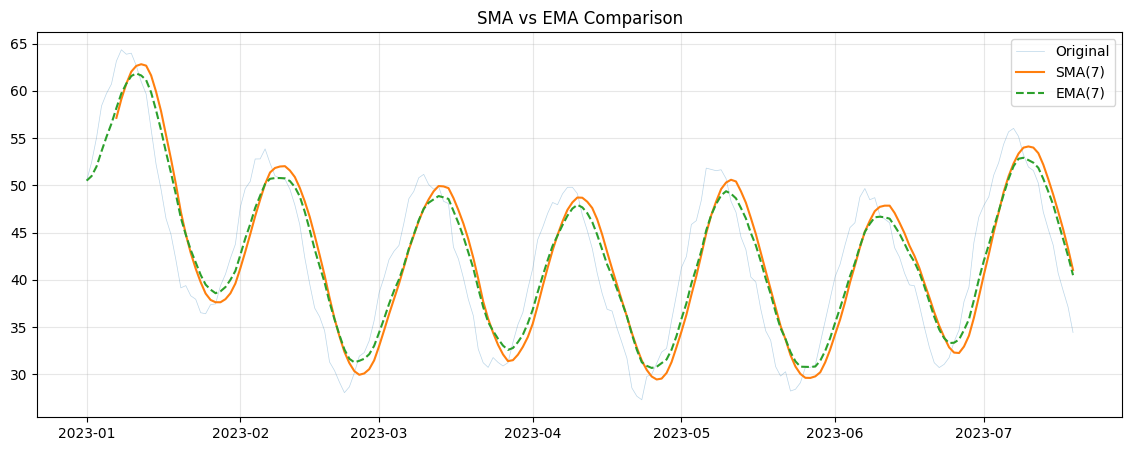

In [ ]:
print("\n" + "=" * 60)
print("Section 2: Exponential Moving Average (EMA)")
print("=" * 60)

df['ema_7'] = df['value'].ewm(span=7, adjust=False).mean()
df['ema_30'] = df['value'].ewm(span=30, adjust=False).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['value'], alpha=0.3, linewidth=0.5, label='Original')
ax.plot(df['rmean_7'], linewidth=1.5, label='SMA(7)')
ax.plot(df['ema_7'], linewidth=1.5, linestyle='--', label='EMA(7)')
ax.set_title('SMA vs EMA Comparison')
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, '03_sma_vs_ema.png'), dpi=100)


## Section 3: Expanding Windows


In [ ]:
print("\n" + "=" * 60)
print("Section 3: Expanding Window")
print("=" * 60)

df['expanding_mean'] = df['value'].expanding().mean()
df['expanding_std'] = df['value'].expanding().std()
print(f"  Expanding mean stabilizes at: {df['expanding_mean'].iloc[-1]:.2f}")
print(f"  Expanding std stabilizes at: {df['expanding_std'].iloc[-1]:.2f}")



Section 3: Expanding Window
  Expanding mean stabilizes at: 42.46
  Expanding std stabilizes at: 8.81


## Section 4: Centered Windows



Section 4: Centered vs Non-Centered Windows


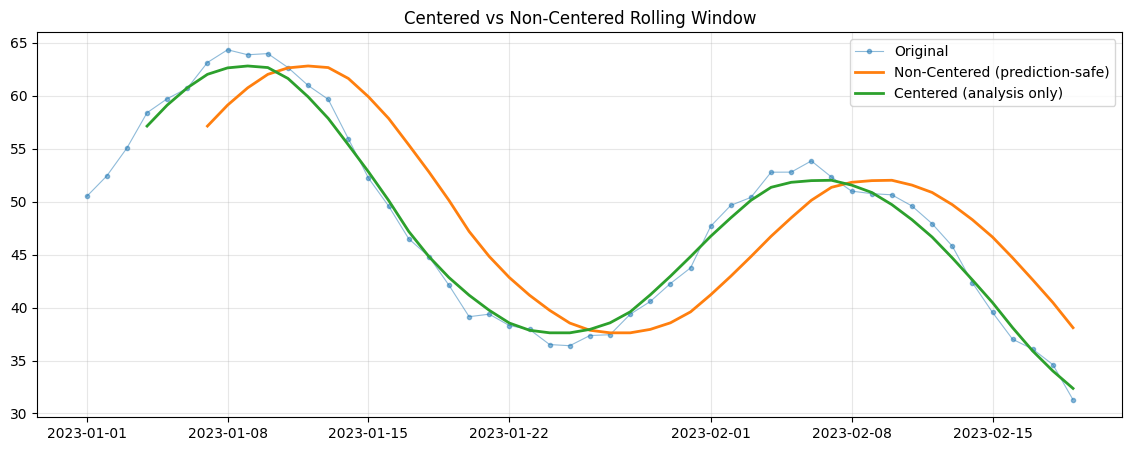

In [ ]:
print("\n" + "=" * 60)
print("Section 4: Centered vs Non-Centered Windows")
print("=" * 60)

# Non-centered (default) - only uses past data
df['non_centered'] = df['value'].rolling(window=7).mean()
# Centered - uses past AND future data (ONLY for analysis, NOT for prediction!)
df['centered'] = df['value'].rolling(window=7, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['value'].iloc[:50], 'o-', markersize=3, linewidth=0.8, label='Original', alpha=0.5)
ax.plot(df['non_centered'].iloc[:50], linewidth=2, label='Non-Centered (prediction-safe)')
ax.plot(df['centered'].iloc[:50], linewidth=2, label='Centered (analysis only)')
ax.set_title('Centered vs Non-Centered Rolling Window')
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, '03_centered_window.png'), dpi=100)


## Section 5: Window Feature Factory


In [ ]:
print("\n" + "=" * 60)
print("Section 5: Window Feature Factory")
print("=" * 60)


def create_window_features(df, target_col, windows):
    """Create comprehensive window-based features."""
    df = df.copy()
    for w in windows:
        roll = df[target_col].shift(1).rolling(w, min_periods=1)
        df[f'{target_col}_rmean_{w}'] = roll.mean()
        df[f'{target_col}_rstd_{w}'] = roll.std()
        df[f'{target_col}_rmin_{w}'] = roll.min()
        df[f'{target_col}_rmax_{w}'] = roll.max()
    return df


df_win = create_window_features(df, 'value', windows=[7, 14, 30])
window_cols = [c for c in df_win.columns if 'rmean' in c or 'rstd' in c]
print(f"  Created {len(window_cols)} window features")
print(f"  Window columns: {window_cols}")



Section 5: Window Feature Factory
  Created 9 window features
  Window columns: ['rmean_7', 'rmean_30', 'rstd_7', 'value_rmean_7', 'value_rstd_7', 'value_rmean_14', 'value_rstd_14', 'value_rmean_30', 'value_rstd_30']


## Section 6: Golden Cross (Trend Detection)



Section 6: Trend Detection with SMA Crossover (Golden Cross)
  Golden/Death crosses detected: 10


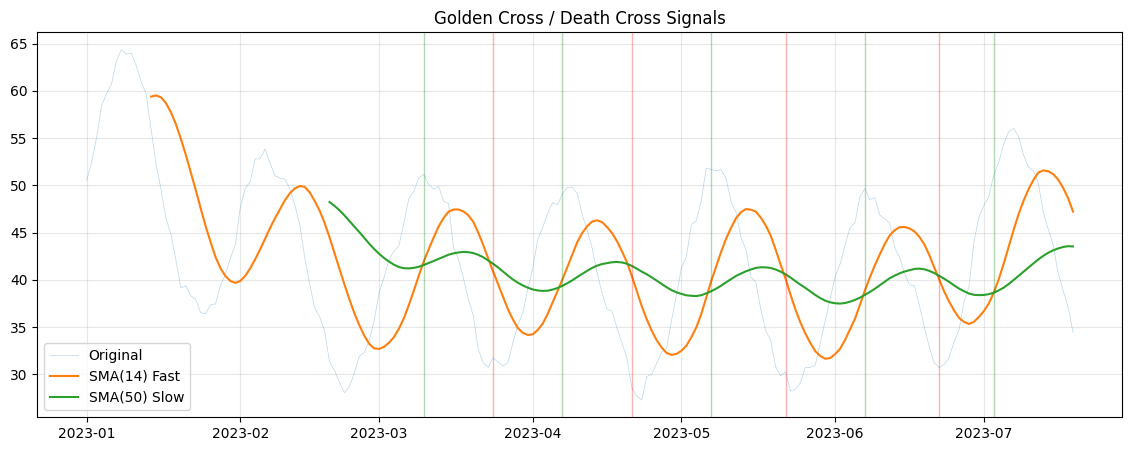

In [ ]:
print("\n" + "=" * 60)
print("Section 6: Trend Detection with SMA Crossover (Golden Cross)")
print("=" * 60)

df['sma_fast'] = df['value'].rolling(14).mean()
df['sma_slow'] = df['value'].rolling(50).mean()
df['signal'] = np.where(df['sma_fast'] > df['sma_slow'], 1, 0)  # 1=uptrend, 0=downtrend
df['cross'] = df['signal'].diff()  # +1 = golden cross (bullish), -1 = death cross (bearish)

crosses = df[df['cross'] != 0]
print(f"  Golden/Death crosses detected: {len(crosses)}")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['value'], alpha=0.3, linewidth=0.5, label='Original')
ax.plot(df['sma_fast'], linewidth=1.5, label='SMA(14) Fast')
ax.plot(df['sma_slow'], linewidth=1.5, label='SMA(50) Slow')
# Mark crosses
for idx in crosses[crosses['cross'] > 0].index:
    ax.axvline(x=idx, color='green', alpha=0.3, linewidth=1)
for idx in crosses[crosses['cross'] < 0].index:
    ax.axvline(x=idx, color='red', alpha=0.3, linewidth=1)
ax.set_title('Golden Cross / Death Cross Signals')
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, '03_golden_cross.png'), dpi=100)


## Section 7: Bollinger Bands (Anomaly Detection)



Section 7: Bollinger Bands for Anomaly Detection
  Bollinger Band anomalies: 16 out of 200 (8.0%)


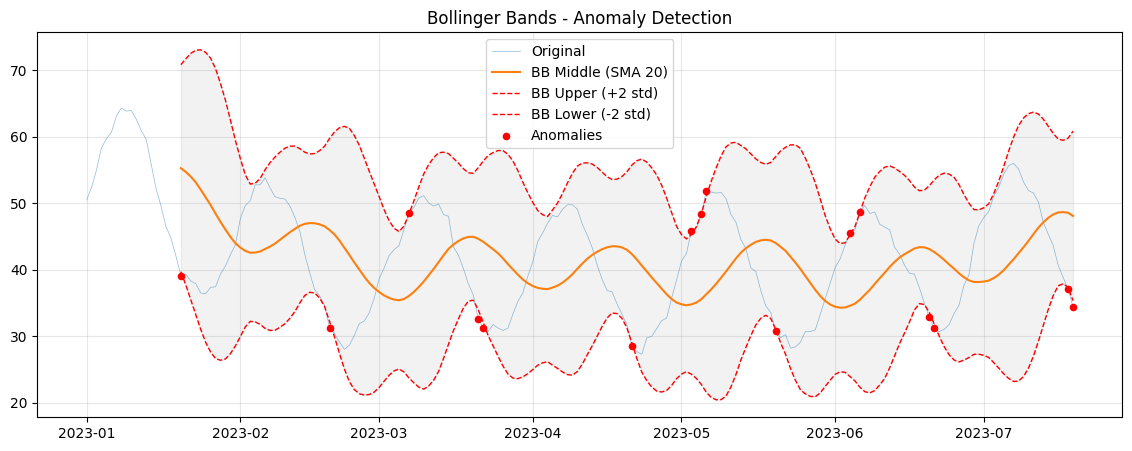

In [ ]:
print("\n" + "=" * 60)
print("Section 7: Bollinger Bands for Anomaly Detection")
print("=" * 60)

window = 20
df['bb_mid'] = df['value'].rolling(window).mean()
df['bb_std'] = df['value'].rolling(window).std()
df['bb_upper'] = df['bb_mid'] + 2 * df['bb_std']
df['bb_lower'] = df['bb_mid'] - 2 * df['bb_std']
df['bb_anomaly'] = (df['value'] > df['bb_upper']) | (df['value'] < df['bb_lower'])

anomalies = df['bb_anomaly'].sum()
print(f"  Bollinger Band anomalies: {anomalies} out of {len(df)} ({anomalies/len(df)*100:.1f}%)")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['value'], alpha=0.5, linewidth=0.5, label='Original')
ax.plot(df['bb_mid'], linewidth=1.5, label='BB Middle (SMA 20)')
ax.plot(df['bb_upper'], 'r--', linewidth=1, label='BB Upper (+2 std)')
ax.plot(df['bb_lower'], 'r--', linewidth=1, label='BB Lower (-2 std)')
ax.fill_between(df.index, df['bb_lower'], df['bb_upper'], alpha=0.1, color='gray')
anomaly_points = df[df['bb_anomaly']]
ax.scatter(anomaly_points.index, anomaly_points['value'], color='red', s=20, zorder=5, label='Anomalies')
ax.set_title('Bollinger Bands - Anomaly Detection')
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, '03_bollinger_bands.png'), dpi=100)


## Section 8: Sliding Window Dataset for ML


In [ ]:
print("\n" + "=" * 60)
print("Section 8: Sliding Window Dataset for DL/ML")
print("=" * 60)


def create_sliding_window_dataset(data, window_size, forecast_horizon=1, stride=1):
    """Create X (windows) and y (targets) for supervised learning."""
    X, y = [], []
    for i in range(0, len(data) - window_size - forecast_horizon + 1, stride):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size + forecast_horizon - 1])
    return np.array(X), np.array(y)


data_arr = df['value'].values
X_sw, y_sw = create_sliding_window_dataset(data_arr, window_size=14, forecast_horizon=1, stride=7)
print(f"  Window size=14, stride=7:")
print(f"    X shape: {X_sw.shape}  (samples, timesteps)")
print(f"    y shape: {y_sw.shape}  (samples,)")

# Non-overlapping windows
X_no, y_no = create_sliding_window_dataset(data_arr, window_size=14, forecast_horizon=1, stride=14)
print(f"  Window size=14, stride=14 (non-overlapping):")
print(f"    X shape: {X_no.shape}")

# Overlapping windows
X_ov, y_ov = create_sliding_window_dataset(data_arr, window_size=14, forecast_horizon=1, stride=1)
print(f"  Window size=14, stride=1 (max overlap):")
print(f"    X shape: {X_ov.shape}")

print("\nDone! Sliding windows analysis complete.")



Section 8: Sliding Window Dataset for DL/ML
  Window size=14, stride=7:
    X shape: (27, 14)  (samples, timesteps)
    y shape: (27,)  (samples,)
  Window size=14, stride=14 (non-overlapping):
    X shape: (14, 14)
  Window size=14, stride=1 (max overlap):
    X shape: (186, 14)

Done! Sliding windows analysis complete.


---
## Differencing Transformations


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer
import os, warnings
warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)


## Create Sample Data


In [ ]:
n = 200
t = np.arange(n)
# Non-stationary data with trend and seasonality
data = 0.2 * t + 10 * np.sin(2 * np.pi * t / 30) + np.random.normal(0, 2, n)
df = pd.DataFrame({'value': data}, index=pd.date_range('2023-01-01', periods=n, freq='D'))
series = df['value']

print("=" * 60)
print("Original Data")
print("=" * 60)
adf_result = adfuller(series.dropna())
print(f"  ADF p-value: {adf_result[1]:.6f} -> {'Stationary' if adf_result[1] < 0.05 else 'Non-Stationary'}")
print(f"  Mean: {series.mean():.2f}, Std: {series.std():.2f}")


Original Data
  ADF p-value: 0.820471 -> Non-Stationary
  Mean: 20.20, Std: 13.62


## Section 1: Differencing Operations



Section 1: Differencing
  First-order diff:  ADF p-value=0.000000, Stationary=True
  Second-order diff: ADF p-value=0.000000, Stationary=True
  Log returns:       ADF p-value=0.000000, Stationary=True
  Seasonal diff(7):  ADF p-value=0.000000, Stationary=True
  Combined diff:     ADF p-value=0.000000, Stationary=True


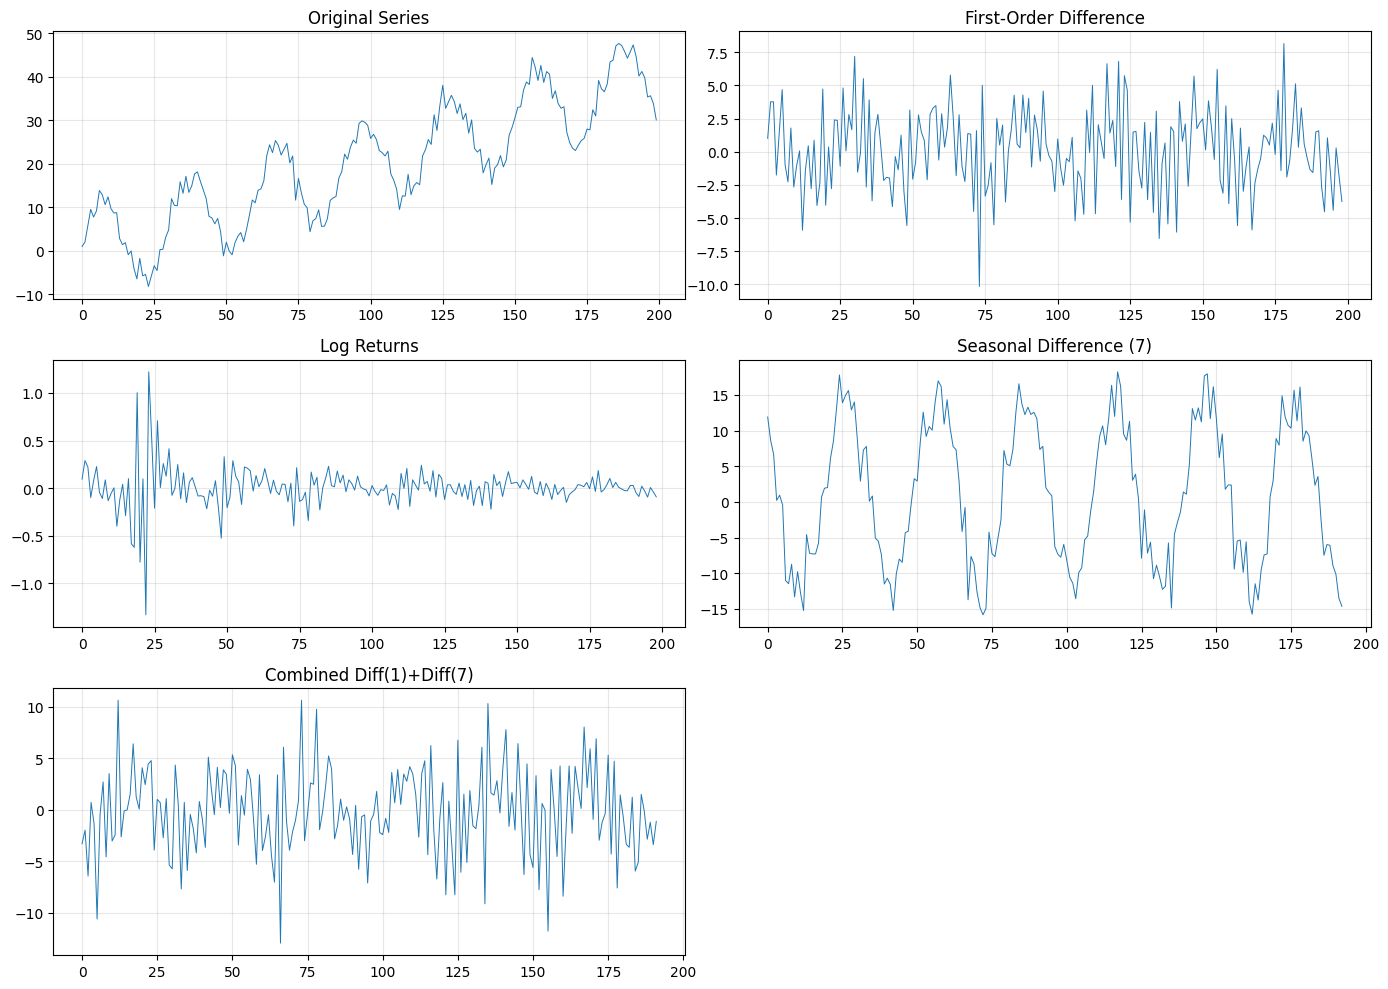

In [ ]:
print("\n" + "=" * 60)
print("Section 1: Differencing")
print("=" * 60)

# First-order differencing
diff_1 = series.diff(1)
adf_d1 = adfuller(diff_1.dropna())
print(f"  First-order diff:  ADF p-value={adf_d1[1]:.6f}, Stationary={adf_d1[1] < 0.05}")

# Second-order differencing
diff_2 = series.diff(2)
adf_d2 = adfuller(diff_2.dropna())
print(f"  Second-order diff: ADF p-value={adf_d2[1]:.6f}, Stationary={adf_d2[1] < 0.05}")

# Log returns (for financial data)
positive_ts = series - series.min() + 1
log_returns = np.log(positive_ts).diff(1)
lr_adf = adfuller(log_returns.dropna())
print(f"  Log returns:       ADF p-value={lr_adf[1]:.6f}, Stationary={lr_adf[1] < 0.05}")

# Seasonal differencing
seasonal_diff = series.diff(7)  # weekly
sd_adf = adfuller(seasonal_diff.dropna())
print(f"  Seasonal diff(7):  ADF p-value={sd_adf[1]:.6f}, Stationary={sd_adf[1] < 0.05}")

# Combined differencing
combined_diff = series.diff(1).diff(7)
cd_adf = adfuller(combined_diff.dropna())
print(f"  Combined diff:     ADF p-value={cd_adf[1]:.6f}, Stationary={cd_adf[1] < 0.05}")

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
plots = [
    (axes[0, 0], series, 'Original Series'),
    (axes[0, 1], diff_1, 'First-Order Difference'),
    (axes[1, 0], log_returns, 'Log Returns'),
    (axes[1, 1], seasonal_diff, 'Seasonal Difference (7)'),
    (axes[2, 0], combined_diff, 'Combined Diff(1)+Diff(7)'),
]
for ax, d, title in plots:
    ax.plot(d.dropna().values if hasattr(d, 'values') else d, linewidth=0.7)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
axes[2, 1].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '04_differencing.png'), dpi=100)


## Section 2: Optimal Differencing Order


In [ ]:
print("\n" + "=" * 60)
print("Section 2: Finding Optimal Differencing Order")
print("=" * 60)


def find_optimal_differencing(series, max_d=3):
    """Find optimal d using ADF test."""
    for d in range(max_d + 1):
        if d == 0:
            test = series.dropna()
        else:
            test = series.diff(d).dropna()
        pval = adfuller(test)[1]
        status = 'Stationary' if pval < 0.05 else 'Non-Stationary'
        print(f"    d={d}: ADF p-value={pval:.6f} -> {status}")
        if pval < 0.05:
            return d
    return max_d


optimal_d = find_optimal_differencing(series)
print(f"  Optimal d: {optimal_d}")

# Over-differencing check
print("\n  Over-differencing variance comparison:")
for d in range(0, 5):
    diffed = series.diff(d).dropna()
    print(f"    d={d}: variance={np.var(diffed):.4f}")



Section 2: Finding Optimal Differencing Order
    d=0: ADF p-value=0.820471 -> Non-Stationary
    d=1: ADF p-value=0.000000 -> Stationary
  Optimal d: 1

  Over-differencing variance comparison:
    d=0: variance=0.0000
    d=1: variance=9.4619
    d=2: variance=15.8820
    d=3: variance=25.9322
    d=4: variance=40.4463


## Section 3: Transformations


In [ ]:
print("\n" + "=" * 60)
print("Section 3: Variance-Stabilizing Transformations")
print("=" * 60)

positive_data = series - series.min() + 1

# Log transform
log_data = np.log(positive_data)
print(f"  Log transform:       std before={series.std():.2f}, after={log_data.std():.3f}")

# Box-Cox
boxcox_data, bc_lambda = stats.boxcox(positive_data)
print(f"  Box-Cox (lambda={bc_lambda:.3f}): std={boxcox_data.std():.3f}")

# Yeo-Johnson (handles negative values)
pt = PowerTransformer(method='yeo-johnson')
yj_data = pt.fit_transform(series.values.reshape(-1, 1)).flatten()
print(f"  Yeo-Johnson:              std={yj_data.std():.3f}")

# Square root
sqrt_data = np.sqrt(positive_data)
print(f"  Square root:              std={sqrt_data.std():.3f}")



Section 3: Variance-Stabilizing Transformations
  Log transform:       std before=13.62, after=0.638
  Box-Cox (lambda=0.806): std=7.202
  Yeo-Johnson:              std=1.000
  Square root:              std=1.374


## Section 4: Scaling Methods



Section 4: Scaling Methods
  StandardScaler:  mean=0.000000, std=1.00
  MinMaxScaler:    min=0.00, max=1.00
  RobustScaler:    median=0.0000, IQR=1.00


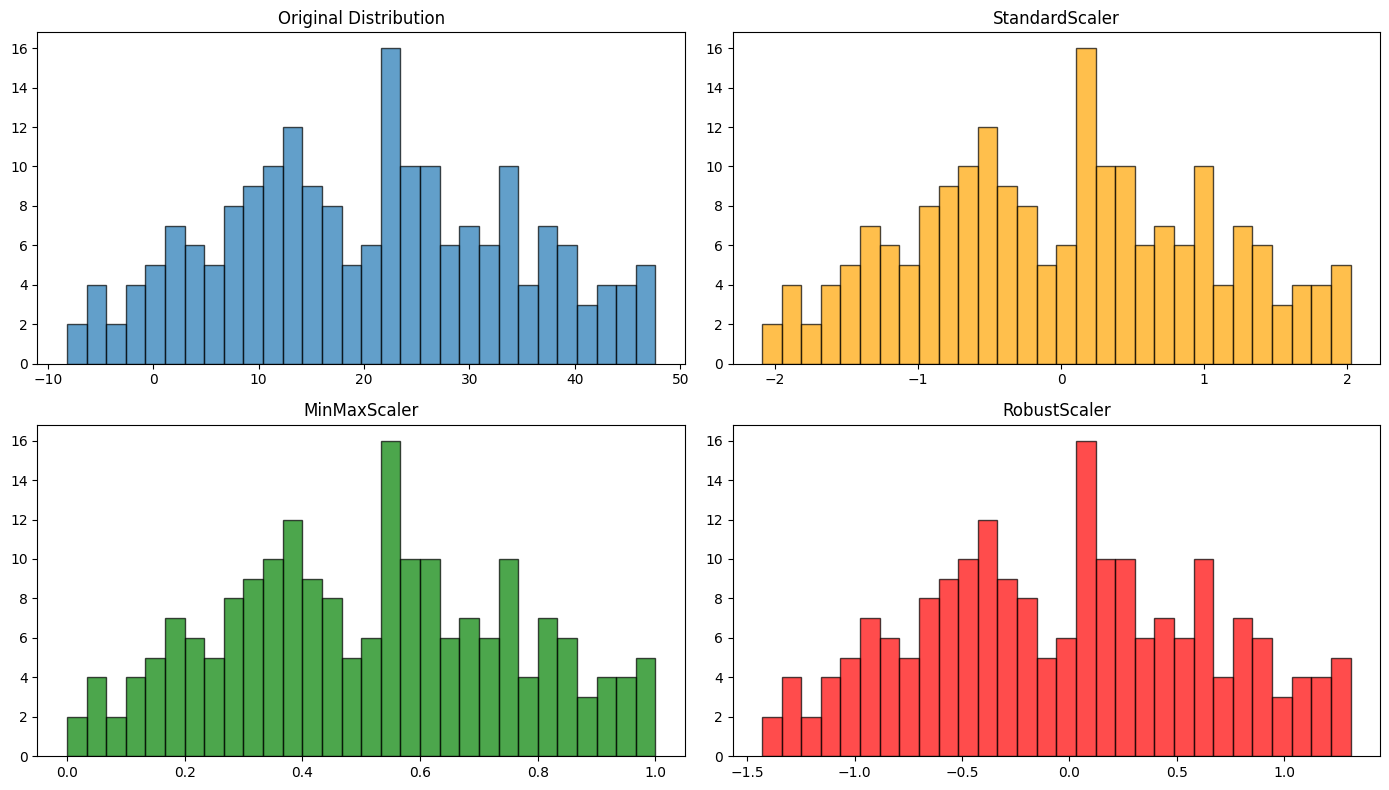

In [ ]:
print("\n" + "=" * 60)
print("Section 4: Scaling Methods")
print("=" * 60)

data_2d = series.values.reshape(-1, 1)

# StandardScaler
ss = StandardScaler()
ss_data = ss.fit_transform(data_2d).flatten()
print(f"  StandardScaler:  mean={ss_data.mean():.6f}, std={ss_data.std():.2f}")

# MinMaxScaler
mms = MinMaxScaler()
mms_data = mms.fit_transform(data_2d).flatten()
print(f"  MinMaxScaler:    min={mms_data.min():.2f}, max={mms_data.max():.2f}")

# RobustScaler (robust to outliers)
rs = RobustScaler()
rs_data = rs.fit_transform(data_2d).flatten()
print(f"  RobustScaler:    median={np.median(rs_data):.4f}, IQR={np.percentile(rs_data,75)-np.percentile(rs_data,25):.2f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].hist(series, bins=30, edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Original Distribution')
axes[0, 1].hist(ss_data, bins=30, edgecolor='black', alpha=0.7, color='orange')
axes[0, 1].set_title('StandardScaler')
axes[1, 0].hist(mms_data, bins=30, edgecolor='black', alpha=0.7, color='green')
axes[1, 0].set_title('MinMaxScaler')
axes[1, 1].hist(rs_data, bins=30, edgecolor='black', alpha=0.7, color='red')
axes[1, 1].set_title('RobustScaler')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '04_scaling_methods.png'), dpi=100)


## Section 5: Transformation Diagnostics


In [ ]:
print("\n" + "=" * 60)
print("Section 5: Diagnosing Transformation Needs")
print("=" * 60)


def diagnose_transformations(series):
    """Analyze which transformations are appropriate."""
    print("  Transformation Diagnostics:")
    # Trend strength
    X = np.arange(len(series)).reshape(-1, 1)
    from sklearn.linear_model import LinearRegression
    model = LinearRegression().fit(X, series.values if hasattr(series, 'values') else series)
    trend_strength = model.score(X, series.values if hasattr(series, 'values') else series)
    print(f"    Trend strength (R-squared): {trend_strength:.4f}")
    print(f"    {'Strong trend -> differencing needed' if trend_strength > 0.3 else 'Weak trend'}")

    # Variance change over time
    half = len(series) // 2
    var_first = np.var(series.iloc[:half] if hasattr(series, 'iloc') else series[:half])
    var_second = np.var(series.iloc[half:] if hasattr(series, 'iloc') else series[half:])
    var_ratio = var_second / var_first if var_first > 0 else 1
    print(f"    Variance ratio (second/first half): {var_ratio:.3f}")
    print(f"    {'Variance instability -> log/Box-Cox needed' if abs(var_ratio - 1) > 0.3 else 'Variance stable'}")

    # Skewness
    skew = stats.skew(series.dropna() if hasattr(series, 'dropna') else series)
    print(f"    Skewness: {skew:.3f}")
    print(f"    {'High skewness -> transformation needed' if abs(skew) > 1 else 'Acceptable skewness'}")


diagnose_transformations(series)



Section 5: Diagnosing Transformation Needs
  Transformation Diagnostics:
    Trend strength (R-squared): 0.7164
    Strong trend -> differencing needed
    Variance ratio (second/first half): 1.077
    Variance stable
    Skewness: 0.062
    Acceptable skewness


## Section 6: Complete Preprocessing Pipeline


In [ ]:
print("\n" + "=" * 60)
print("Section 6: TimeSeriesPreprocessor Class")
print("=" * 60)


class TimeSeriesPreprocessor:
    """Complete preprocessing pipeline for time series."""

    def __init__(self, diff_order=0, seasonal_period=None, transform='none', scaler='standard'):
        self.diff_order = diff_order
        self.seasonal_period = seasonal_period
        self.transform = transform
        self.scaler_name = scaler
        self.scaler = None
        self._first_value = None
        self._seasonal_values = None

    def fit_transform(self, series):
        result = series.copy() if hasattr(series, 'copy') else series.copy()

        # Save original first values for inverse
        if self.diff_order > 0:
            self._first_value = result.iloc[:self.diff_order] if hasattr(result, 'iloc') else result[:self.diff_order]
            for _ in range(self.diff_order):
                result = result.diff(1)

        if self.seasonal_period:
            self._seasonal_values = result.iloc[:self.seasonal_period] if hasattr(result, 'iloc') else result[:self.seasonal_period]
            result = result.diff(self.seasonal_period)

        result = result.dropna() if hasattr(result, 'dropna') else pd.Series(result).dropna()

        # Transform
        if self.transform == 'log':
            min_val = result.min()
            offset = abs(min_val) + 1 if min_val <= 0 else 0
            result = np.log(result + offset)
        elif self.transform == 'boxcox':
            min_val = result.min()
            offset = abs(min_val) + 1 if min_val <= 0 else 0
            result, _ = stats.boxcox(result + offset)

        # Scale
        if self.scaler_name == 'standard':
            self.scaler = StandardScaler()
        elif self.scaler_name == 'minmax':
            self.scaler = MinMaxScaler()
        elif self.scaler_name == 'robust':
            self.scaler = RobustScaler()
        else:
            self.scaler = None

        if self.scaler:
            result_2d = result.values.reshape(-1, 1) if hasattr(result, 'values') else np.array(result).reshape(-1, 1)
            result_scaled = self.scaler.fit_transform(result_2d).flatten()
            return pd.Series(result_scaled) if hasattr(result, 'index') else result_scaled
        return result


preprocessor = TimeSeriesPreprocessor(diff_order=1, transform='log', scaler='standard')
processed = preprocessor.fit_transform(series)
print(f"  Input shape: {len(series)}, Output shape: {len(processed)}")
print(f"  Processed mean={processed.mean():.4f}, std={processed.std():.4f}")



Section 6: TimeSeriesPreprocessor Class
  Input shape: 200, Output shape: 199
  Processed mean=-0.0000, std=1.0025


## Section 7: Compare All Methods


In [ ]:
print("\n" + "=" * 60)
print("Section 7: Comparing All Transformation Methods")
print("=" * 60)

methods = {
    'Original': series.values if hasattr(series, 'values') else series,
    'Differenced': diff_1.dropna().values if hasattr(diff_1, 'dropna') else diff_1[~np.isnan(diff_1)],
    'Log': log_data.values if hasattr(log_data, 'values') else log_data,
    'Box-Cox': boxcox_data,
    'StandardScaler': ss_data,
    'MinMaxScaler': mms_data,
}

for name, d in methods.items():
    arr = d.values if hasattr(d, 'values') else d
    arr = arr[~np.isnan(arr)]
    result = adfuller(arr)
    print(f"  {name:20s}: ADF p-value={result[1]:.6f}, Stationary={result[1] < 0.05}")

print("\nDone! Differencing & transformations analysis complete.")



Section 7: Comparing All Transformation Methods
  Original            : ADF p-value=0.820471, Stationary=False
  Differenced         : ADF p-value=0.000000, Stationary=True
  Log                 : ADF p-value=0.244512, Stationary=False
  Box-Cox             : ADF p-value=0.762297, Stationary=False
  StandardScaler      : ADF p-value=0.820471, Stationary=False
  MinMaxScaler        : ADF p-value=0.820471, Stationary=False

Done! Differencing & transformations analysis complete.


---
## Part-2 Complete!

All lessons finished successfully.
